In [1]:
import perf
import pandas as pd

In [2]:
perf.system.info()

,cpu,core,numa,arch,platform,vendor,model,family,stepping,freq,L1i,L1d,L2,L3
0,0,0,0,x86_64,Linux-6.2.0-39-generic-x86_64-with-glibc2.37,12th Gen Intel(R) Core(TM) i7-12650H,154,6,3,2688000000,32Kb,48Kb,1280Kb,24576Kb
1,1,4,0,x86_64,Linux-6.2.0-39-generic-x86_64-with-glibc2.37,12th Gen Intel(R) Core(TM) i7-12650H,154,6,3,2688000000,32Kb,48Kb,1280Kb,24576Kb
2,2,8,0,x86_64,Linux-6.2.0-39-generic-x86_64-with-glibc2.37,12th Gen Intel(R) Core(TM) i7-12650H,154,6,3,2688000000,32Kb,48Kb,1280Kb,24576Kb
3,3,12,0,x86_64,Linux-6.2.0-39-generic-x86_64-with-glibc2.37,12th Gen Intel(R) Core(TM) i7-12650H,154,6,3,2688000000,32Kb,48Kb,1280Kb,24576Kb
4,4,16,0,x86_64,Linux-6.2.0-39-generic-x86_64-with-glibc2.37,12th Gen Intel(R) Core(TM) i7-12650H,154,6,3,2688000000,32Kb,48Kb,1280Kb,24576Kb
5,5,20,0,x86_64,Linux-6.2.0-39-generic-x86_64-with-glibc2.37,12th Gen Intel(R) Core(TM) i7-12650H,154,6,3,2688000000,32Kb,48Kb,1280Kb,24576Kb
6,6,28,0,x86_64,Linux-6.2.0-39-generic-x86_64-with-glibc2.37,12th Gen Intel(R) Core(TM) i7-12650H,154,6,3,2688000000,64Kb,32Kb,2048Kb,24576Kb
7,7,29,0,x86_64,Linux-6.2.0-39-generic-x86_64-with-glibc2.37,12th Gen Intel(R) Core(TM) i7-12650H,154,6,3,2688000000,64Kb,32Kb,2048Kb,24576Kb
8,8,30,0,x86_64,Linux-6.2.0-39-generic-x86_64-with-glibc2.37,12th Gen Intel(R) Core(TM) i7-12650H,154,6,3,2688000000,64Kb,32Kb,2048Kb,24576Kb
9,9,31,0,x86_64,Linux-6.2.0-39-generic-x86_64-with-glibc2.37,12th Gen Intel(R) Core(TM) i7-12650H,154,6,3,2688000000,64Kb,32Kb,2048Kb,24576Kb


In [3]:
perf.system.tune()

,setting,path,before,after
0,aslr,/proc/sys/kernel/randomize_va_space,off,off
1,governor,/sys/devices/system/cpu/cpu*/cpufreq/scaling_g...,performance,performance
2,energy_performance_preference,/sys/devices/system/cpu/cpu*/cpufreq/energy_pe...,performance,performance
3,cpu_frequency,/sys/devices/system/cpu/cpu*/cpufreq/scaling_{...,4.6GHz..4.6GHz;4.7GHz..4.7GHz;3.5GHz..3.5GHz,4.6GHz..4.6GHz;4.7GHz..4.7GHz;3.5GHz..3.5GHz
4,turbo,/sys/devices/system/cpu/intel_pstate/no_turbo,on,on
5,turbo_msr,/dev/cpu/*/msr,,on
6,boost,/sys/devices/system/cpu/cpufreq/boost,,on
7,rdpmc,/sys/devices/*/rdpmc,,
8,smt,/sys/devices/system/cpu/smt/control,on,on
9,nmi_watchdog,/proc/sys/kernel/nmi_watchdog,off,off


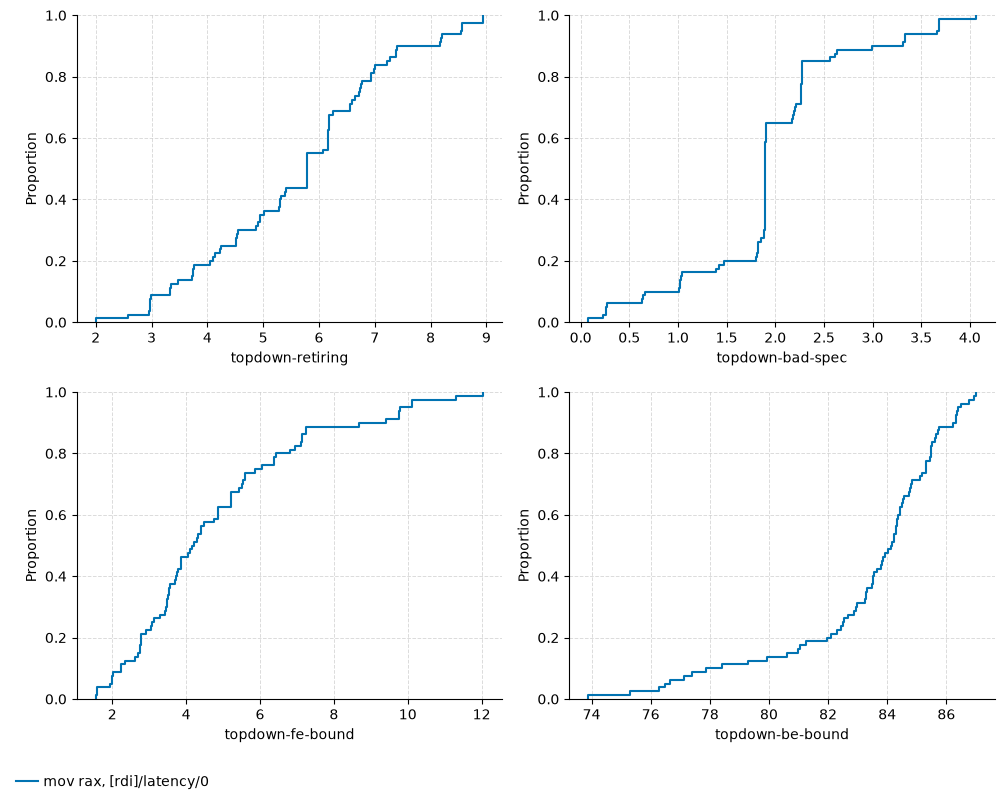

[]

In [4]:
perf.plot(
    perf.benchmark(
        asm="mov rax, [rdi]",
        mode=["latency"],
        event=["topdown*"],
        config={"dcache": ["hot", "warm", "cool", "cold"], "icache": "hot", "dtlb": "hot", "itlb": "hot"},
    )
)

In [5]:
hot = perf.benchmark(
    asm="mov rax, [rdi]",
    mode=["latency"],
    event=["cycles"],
    config={
        "dcache": "hot",
        "icache": "hot",
        "dtlb": "hot",
        "itlb": "hot"
    },
    name="hot",
)
hot

config.backend.loop.probes  config.backend.loop.runs  \
file name mode                                                            
NaN  hot  latency                           3                        10   
          latency                           3                        10   
          latency                           3                        10   
          latency                           3                        10   
          latency                           3                        10   
...                                       ...                       ...   
          latency                           3                        10   
          latency                           3                        10   
          latency                           3                        10   
          latency                           3                        10   
          latency                           3                        10   

                   config.backend.loop.target config.branch  \
file name mode                                                
NaN  hot  latency                        0.01   predictable   
          latency                        0.01   predictable   
          latency                        0.01   predictable   
          latency                        0.01   predictable   
          latency                        0.01   predictable   
...                                       ...           ...   
          latency                        0.01   predictable   
          latency                        0.01   predictable   
          latency                        0.01   predictable   
          latency                        0.01   predictable   
          latency                        0.01   predictable   

                   config.code.align config.dcache config.dtlb  \
file name mode                                                   
NaN  hot  latency                  1           hot         hot   
          latency                  1           hot         hot   
          latency                  1           hot         hot   
          latency                  1           hot         hot   
          latency                  1           hot         hot   
...                              ...           ...         ...   
          latency                 16           hot         hot   
          latency                 16           hot         hot   
          latency                 16           hot         hot   
          latency                 16           hot         hot   
          latency                 16           hot         hot   

                   config.external.lib  config.external.stderr  \
file name mode                                                   
NaN  hot  latency                False                   False   
          latency                False                   False   
          latency                False                   False   
          latency                False                   False   
          latency                False                   False   
...                                ...                     ...   
          latency                False                   False   
          latency                False                   False   
          latency                False                   False   
          latency                False                   False   
          latency                False                   False   

                   config.external.stdout  ...  config.samples config.seed  \
file name mode                             ...                               
NaN  hot  latency                   False  ...             100           0   
          latency                   False  ...             100           0   
          latency                   False  ...             100           0   
          latency                   False  ...             100           0   
          latency                   F

In [6]:
cold = perf.benchmark(
    asm="mov rax, [rdi]",
    mode=["latency"],
    event=["cycles"],
    config={
        "dcache": ["hot", "warm", "cool", "cold"],
        "icache": "hot",
        "dtlb": "hot",
        "itlb": "hot",
    },
    name="cold",
)
cold

config.backend.loop.probes  config.backend.loop.runs  \
file name mode                                                            
NaN  cold latency                           3                        10   
          latency                           3                        10   
          latency                           3                        10   
          latency                           3                        10   
          latency                           3                        10   
...                                       ...                       ...   
          latency                           3                        10   
          latency                           3                        10   
          latency                           3                        10   
          latency                           3                        10   
          latency                           3                        10   

                   config.backend.loop.target config.branch  \
file name mode                                                
NaN  cold latency                        0.01   predictable   
          latency                        0.01   predictable   
          latency                        0.01   predictable   
          latency                        0.01   predictable   
          latency                        0.01   predictable   
...                                       ...           ...   
          latency                        0.01   predictable   
          latency                        0.01   predictable   
          latency                        0.01   predictable   
          latency                        0.01   predictable   
          latency                        0.01   predictable   

                   config.code.align config.dcache config.dtlb  \
file name mode                                                   
NaN  cold latency                  1           hot         hot   
          latency                  1           hot         hot   
          latency                  1           hot         hot   
          latency                  1           hot         hot   
          latency                  1           hot         hot   
...                              ...           ...         ...   
          latency                 16          cold         hot   
          latency                 16          cold         hot   
          latency                 16          cold         hot   
          latency                 16          cold         hot   
          latency                 16          cold         hot   

                   config.external.lib  config.external.stderr  \
file name mode                                                   
NaN  cold latency                False                   False   
          latency                False                   False   
          latency                False                   False   
          latency                False                   False   
          latency                False                   False   
...                                ...                     ...   
          latency                False                   False   
          latency                False                   False   
          latency                False                   False   
          latency                False                   False   
          latency                False                   False   

                   config.external.stdout  ...  config.samples config.seed  \
file name mode                             ...                               
NaN  cold latency                   False  ...             100           0   
          latency                   False  ...             100           0   
          latency                   False  ...             100           0   
          latency                   False  ...             100           0   
          latency                   F

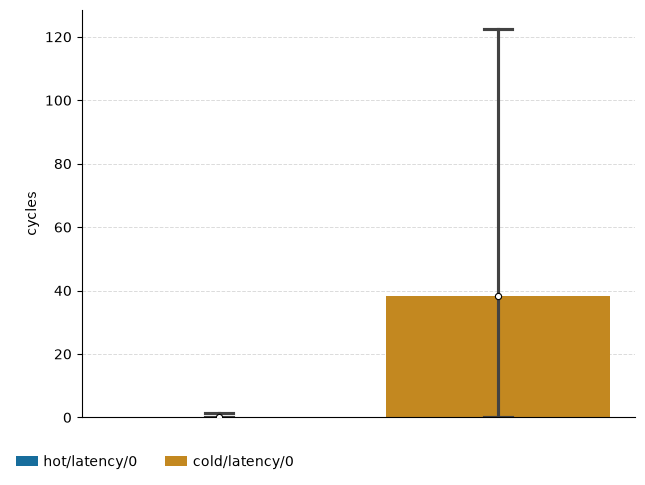

[]

In [7]:
perf.plot(pd.concat([hot, cold]), type="bar")